# TP 3 · Construire des alertes utiles

AI4I 2020. On reprend les splits et le preprocessing du TP 1.

**Objectif :** un système qui lance une **alerte** avant une panne. On compare une baseline, une logistic regression et un arbre de profondeur 3, puis on choisit un **threshold** (seuil de décision).

## 0. Reprise du TP 1 : X, y, splits 60/20/20 et preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

df = pd.read_csv("data/ai4i2020.csv")

TARGET = "Machine failure"
NUM_COLS = ["Torque [Nm]", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Tool wear [min]"]
CAT_COLS = ["Type"]
FEATURES = NUM_COLS + CAT_COLS

X = df[FEATURES]
Y = df[TARGET]

X_train, X_tmp, Y_train, Y_tmp = train_test_split(X, Y, test_size=0.4, stratify=Y, random_state=42)
X_val, X_test, Y_val, Y_test   = train_test_split(X_tmp, Y_tmp, test_size=0.5, stratify=Y_tmp, random_state=42)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])

print(len(X_train), len(X_val), len(X_test))
print("pannes dans la validation :", Y_val.sum(), "sur", len(Y_val))

6000 2000 2000
pannes dans la validation : 68 sur 2000


## 1. Baseline : toujours « normal »

`DummyClassifier(strategy="most_frequent")` ignore les features et prédit toujours la classe la plus fréquente : 0, « pas de panne ».

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, Y_train)
pred_dummy = dummy.predict(X_val)

print("accuracy :", round(accuracy_score(Y_val, pred_dummy), 3))
print("recall   :", recall_score(Y_val, pred_dummy))
print(confusion_matrix(Y_val, pred_dummy))

accuracy : 0.966
recall   : 0.0
[[1932    0]
 [  68    0]]


**Lecture :** 96,6 % d'accuracy… et **0 panne détectée** (recall = 0). Comme 96,6 % des machines ne tombent pas en panne, répondre « normal » à tout donne une excellente accuracy, mais ce système d'alerte ne sert à rien.

👉 Sur une classe rare, **l'accuracy ne sert presque à rien**. On regarde la **precision** et le **recall** de la classe panne.

## 2. Logistic regression et arbre de profondeur 3

- **Logistic regression** : une régression linéaire suivie d'une sigmoid. Elle produit un **score entre 0 et 1**, qu'on lit comme une probabilité de panne.
- **Arbre de décision, `max_depth=3`** : au plus trois questions du type « Torque ≤ 13,5 ? » avant de décider. Il se lit facilement.

Chaque modèle a sa propre copie du preprocessing (`clone`), et le `fit` du pipeline l'ajuste sur le train uniquement.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text

logit = make_pipeline(clone(preprocess), LogisticRegression(max_iter=1000))
tree  = make_pipeline(clone(preprocess), DecisionTreeClassifier(max_depth=3, random_state=42))

logit.fit(X_train, Y_train)
tree.fit(X_train, Y_train)

# Les règles apprises par l'arbre
names = tree[0].get_feature_names_out()
print(export_text(tree[-1], feature_names=list(names)))

|--- num__Torque [Nm] <= 2.37
|   |--- num__Torque [Nm] <= -2.64
|   |   |--- cat__Type_H <= 0.50
|   |   |   |--- class: 1
|   |   |--- cat__Type_H >  0.50
|   |   |   |--- class: 0
|   |--- num__Torque [Nm] >  -2.64
|   |   |--- num__Rotational speed [rpm] <= -0.88
|   |   |   |--- class: 0
|   |   |--- num__Rotational speed [rpm] >  -0.88
|   |   |   |--- class: 0
|--- num__Torque [Nm] >  2.37
|   |--- num__Rotational speed [rpm] <= -1.78
|   |   |--- num__Process temperature [K] <= 0.74
|   |   |   |--- class: 0
|   |   |--- num__Process temperature [K] >  0.74
|   |   |   |--- class: 1
|   |--- num__Rotational speed [rpm] >  -1.78
|   |   |--- num__Torque [Nm] <= 2.49
|   |   |   |--- class: 0
|   |   |--- num__Torque [Nm] >  2.49
|   |   |   |--- class: 1



**Lire l'arbre :** les seuils sont en unités **standardisées** (le StandardScaler est passé avant). `Torque ≤ 2,37` veut dire « torque ≤ moyenne + 2,37 écarts-types » ≈ 40 + 2,37 × 10 ≈ **64 Nm**. L'arbre retrouve ce qu'on avait vu au TP 0 : il isole les **torques très hauts** et les **très bas** (`≤ -2,64` ≈ 13,5 Nm), avec la vitesse de rotation en complément.
*(Un arbre n'a pas besoin de scaling : il compare des valeurs, il ne les additionne pas. On le garde ici pour utiliser le même pipeline que la logit.)*

## 3. Comparer confusion matrices, precision et recall sur la validation

Rappel :
- **precision** = parmi les **alertes**, combien de vraies pannes ? (« est-ce que je dérange les techniciens pour rien ? »)
- **recall** = parmi les **vraies pannes**, combien détectées ? (« est-ce que je rate des pannes ? »)
- **F1** = un compromis entre les deux.

`predict` utilise par défaut un threshold de **0,5**.

In [4]:
models = {"dummy": dummy, "logit": logit, "tree (depth 3)": tree}

rows = []
for name, m in models.items():
    p = m.predict(X_val)
    tn, fp, fn, tp = confusion_matrix(Y_val, p).ravel()
    rows.append({"modèle": name,
                 "accuracy": accuracy_score(Y_val, p),
                 "precision": precision_score(Y_val, p, zero_division=0),
                 "recall": recall_score(Y_val, p),
                 "f1": f1_score(Y_val, p, zero_division=0),
                 "alertes": tp + fp, "pannes détectées": tp,
                 "pannes ratées": fn, "fausses alertes": fp})
comparaison = pd.DataFrame(rows).set_index("modèle")
comparaison.round(3)

,accuracy,precision,recall,f1,alertes,pannes détectées,pannes ratées,fausses alertes
modèle,,,,,,,,
dummy,0.966,0.000,0.000,0.000,0,0,68,0
logit,0.971,0.727,0.235,0.356,22,16,52,6
tree (depth 3),0.970,0.684,0.191,0.299,19,13,55,6


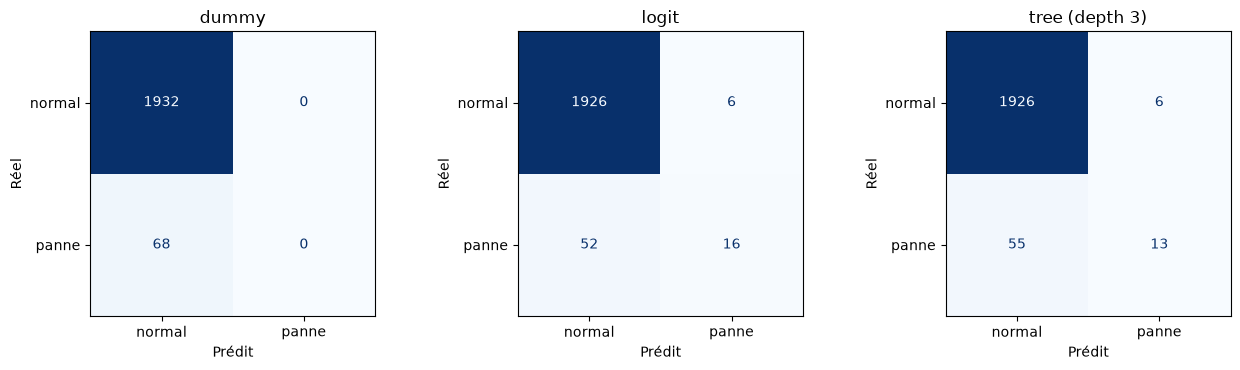

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        Y_val, m.predict(X_val), display_labels=["normal", "panne"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
plt.tight_layout(); plt.show()

## 4. Tester les thresholds 0,3 / 0,5 / 0,7 et justifier le choix

Un modèle ne donne pas directement une décision : il donne un **score** (`predict_proba`). Le **threshold** transforme ce score en décision : alerte si score ≥ threshold.

- threshold **bas** → plus d'alertes → recall ↑, precision ↓
- threshold **haut** → moins d'alertes, plus souvent justes → precision ↑, mais plus de pannes ratées

Le choix se fait **sur la validation**, selon le coût de chaque erreur.

In [6]:
scores = {"logit": logit.predict_proba(X_val)[:, 1],
          "tree (depth 3)": tree.predict_proba(X_val)[:, 1]}

rows = []
for name, s in scores.items():
    for t in [0.3, 0.5, 0.7]:
        alert = (s >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(Y_val, alert).ravel()
        rows.append({"modèle": name, "threshold": t,
                     "precision": precision_score(Y_val, alert, zero_division=0),
                     "recall": recall_score(Y_val, alert),
                     "alertes": tp + fp, "pannes détectées": tp,
                     "pannes ratées": fn, "fausses alertes": fp,
                     "coût (50·FN + FP)": 50 * fn + fp})
thresholds = pd.DataFrame(rows).set_index(["modèle", "threshold"])
thresholds.round(3)

precision  recall  alertes  pannes détectées  \
modèle         threshold                                                 
logit          0.3            0.489   0.324       45                22   
               0.5            0.727   0.235       22                16   
               0.7            1.000   0.132        9                 9   
tree (depth 3) 0.3            0.591   0.191       22                13   
               0.5            0.684   0.191       19                13   
               0.7            0.684   0.191       19                13   

                          pannes ratées  fausses alertes  coût (50·FN + FP)  
modèle         threshold                                                     
logit          0.3                   46               23               2323  
               0.5                   52                6               2606  
               0.7                   59                0               2950  
tree (depth 3) 0.3                   55                9               2759  
               0.5                   55                6               2756  
               0.7                   55                6               2756

La dernière colonne est un **coût fictif** (bonus de la diapositive 130) : on suppose qu'une **panne ratée coûte 50 fois plus** qu'une fausse alerte (arrêt de production, réparation lourde, contre un technicien qui se déplace pour rien). Plus le coût est bas, mieux c'est.

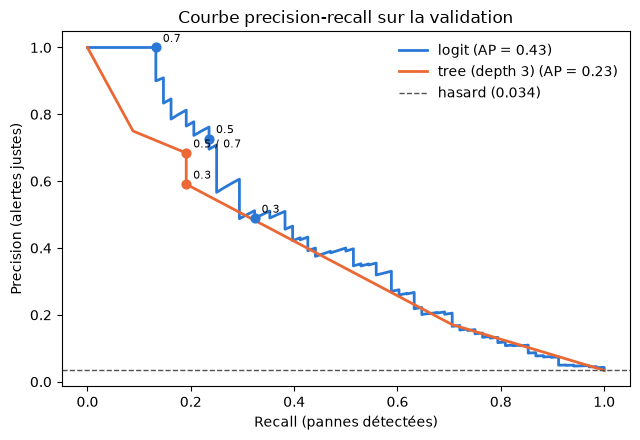

In [7]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(6.5, 4.5))
colors = {"logit": "#2a78d6", "tree (depth 3)": "#eb6834"}
for name, s in scores.items():
    prec, rec, thr = precision_recall_curve(Y_val, s)
    ap = average_precision_score(Y_val, s)
    ax.plot(rec, prec, color=colors[name], lw=2, label=f"{name} (AP = {ap:.2f})")
    # marquer les thresholds 0,3 / 0,5 / 0,7
    # (des thresholds qui tombent sur le même point sont regroupés dans une seule étiquette)
    points = {}
    for t in [0.3, 0.5, 0.7]:
        a = (s >= t).astype(int)
        if a.sum():
            xy = (recall_score(Y_val, a), precision_score(Y_val, a))
            points.setdefault(xy, []).append(str(t))
    for xy, ts in points.items():
        ax.scatter(*xy, color=colors[name], s=40, zorder=3)
        ax.annotate(" / ".join(ts), xy, textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(Y_val.mean(), ls="--", color="#52514e", lw=1, label=f"hasard ({Y_val.mean():.3f})")
ax.set_xlabel("Recall (pannes détectées)")
ax.set_ylabel("Precision (alertes justes)")
ax.set_title("Courbe precision-recall sur la validation")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Évaluation finale sur le test (une seule fois, avec le choix déjà fait)

In [8]:
CHOIX_MODELE, CHOIX_T = logit, 0.3

s_test = CHOIX_MODELE.predict_proba(X_test)[:, 1]
alert_test = (s_test >= CHOIX_T).astype(int)
tn, fp, fn, tp = confusion_matrix(Y_test, alert_test).ravel()
print(f"Test — precision {precision_score(Y_test, alert_test):.2f} | recall {recall_score(Y_test, alert_test):.2f}")
print(f"{tp} pannes détectées sur {tp + fn}, {fp} fausses alertes, {fn} pannes ratées")

Test — precision 0.64 | recall 0.37
25 pannes détectées sur 68, 14 fausses alertes, 43 pannes ratées


## Conclusion

**Comparaison (validation, threshold 0,5)** : 68 pannes sur 2000 machines.

| Modèle | Precision | Recall | Pannes détectées | Fausses alertes |
|---|---|---|---|---|
| Baseline « toujours normal » | – | 0 % | 0 / 68 | 0 |
| Logistic regression | 73 % | 24 % | 16 / 68 | 6 |
| Arbre profondeur 3 | 68 % | 19 % | 13 / 68 | 6 |

À 0,5, la **logistic regression** fait mieux que l'arbre sur les deux tableaux : plus de pannes trouvées, autant de fausses alertes.

**Thresholds (logit)** :
- **0,7** : precision 100 %, mais seulement 9 pannes détectées sur 68 → trop prudent.
- **0,5** : 16 pannes détectées, 6 fausses alertes.
- **0,3** : **22 pannes détectées**, 23 fausses alertes (precision 49 %).

Pour l'arbre, 0,5 et 0,7 donnent exactement le même résultat : un arbre de profondeur 3 n'a que 8 feuilles, donc seulement quelques scores possibles. Changer le threshold ne change rien tant qu'on ne franchit pas un de ces scores.

**Choix : logistic regression, threshold 0,3.**
En maintenance, **rater une panne coûte bien plus cher** qu'une fausse alerte (arrêt de production contre un contrôle inutile). On accepte donc plus d'alertes pour trouver plus de pannes : à 0,3, on gagne 6 pannes détectées pour 17 fausses alertes de plus. Avec un coût fictif « panne ratée = 50 × fausse alerte », 0,3 est aussi le threshold le moins coûteux des six combinaisons (2323 contre 2606 à 0,5).

**Test (évalué une seule fois, après le choix)** : precision 64 %, recall 37 % → 25 pannes détectées sur 68, 14 fausses alertes. Du même ordre que sur la validation : le choix tient sur des données jamais vues.

**Limite :** même au meilleur threshold testé, **près de deux pannes sur trois restent ratées**. Baisser encore le threshold (0,1 ou 0,2), utiliser `class_weight="balanced"` ou un arbre plus profond augmenterait le recall, au prix de beaucoup plus d'alertes.